# Ocean temperature deltas used for the pi-co2 initial conditions

Follows `FigS1.ipynb`, but for the pi-co2 perturbation in `/gf5/predict/AWH012_LEACH_NASTORM/IC-PREP/output/pi-co2`.

- map: `sstdelta/sstdelta.grib` (IFS SST delta), regridded from the reduced Gaussian grid to 0.25°
- depth panels: perturbed minus operational NEMO restart `tn`, averaged over opa0-4. The deltas are precomputed by `data_scripts/ocean_deltas_THESIS_INTRO.py`, because each restart is ~17 GB uncompressed.

# Dependencies

In [1]:
import numpy as np
import xarray as xr
import subprocess
import os
import sys
import matplotlib
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
from cartopy import crs
sys.path.insert(0, os.path.abspath('..'))  # stormeunice is not pip-installed in this kernel
import stormeunice as eun

style = eun.style
style.set_style()
%matplotlib inline

# Import data

In [5]:
EXPERIMENT = 'pi-co2'
INI = '20220214'
DATA_DIR = '/gf5/predict/AWH028_ERMIS_BABET/Eunice/'
SST_DELTA = '/gf5/predict/AWH012_LEACH_NASTORM/IC-PREP/output/{}/sstdelta/sstdelta.grib'.format(EXPERIMENT)

# ensemble-mean (opa0-4) restart tn delta, from data_scripts/ocean_deltas_THESIS_INTRO.py
ds = xr.open_dataset(os.path.join(DATA_DIR, 'ocean_delta_tn_{}_{}.nc'.format(EXPERIMENT, INI)))

# the SST delta is on the reduced Gaussian grid: regrid bilinearly to 0.25 deg
sst_file = os.path.join(DATA_DIR, 'sstdelta_{}_025deg.nc'.format(EXPERIMENT))
if not os.path.exists(sst_file):
    subprocess.run(['cdo', '-s', '-f', 'nc4', 'remapbil,r1440x720', '-setgridtype,regular', SST_DELTA, sst_file], check=True)
sst = xr.open_dataset(sst_file)
sst = sst[list(sst.data_vars)[0]].squeeze()  # named dte or var161 depending on cdo version
# cyclic point so contourf has no seam at 0E
sst = -1 * xr.concat([sst, sst.isel(lon=0).assign_coords(lon=360.)], dim='lon')

# Zonal mean and global mean profile

The ORCA025 grid is curvilinear, so the zonal mean is an area-weighted mean over 1° bins of `gphit`.

In [6]:
delta = ds.delta_tn.where(ds.tmask == 1).values  # (z, y, x)
w = (ds.e1t * ds.e2t).values * (ds.tmask.values == 1)  # ocean cell area per level
depth = ds.depth.values

## global mean profile
profile = -1 * xr.DataArray(np.nansum(delta * w, axis=(1, 2)) / w.sum(axis=(1, 2)), coords={'z': depth}, dims='z')

## zonal mean
lat_edges = np.arange(-80, 91, 1)
lat_bin = np.digitize(ds.gphit.values, lat_edges).ravel() - 1
valid = (lat_bin >= 0) & (lat_bin < lat_edges.size - 1)
zonal = np.full((lat_edges.size - 1, depth.size), np.nan)
for k in range(depth.size):
    num = np.bincount(lat_bin[valid], weights=np.nan_to_num(delta[k] * w[k]).ravel()[valid], minlength=zonal.shape[0])
    den = np.bincount(lat_bin[valid], weights=w[k].ravel()[valid], minlength=zonal.shape[0])
    with np.errstate(invalid='ignore', divide='ignore'):
        zonal[:, k] = np.where(den > 0, num / den, np.nan)
zonal = -1 * xr.DataArray(zonal, coords={'lat': 0.5 * (lat_edges[1:] + lat_edges[:-1]), 'z': depth}, dims=('lat', 'z'))

/home/e/ermis/nobackups/miniforge3/envs/babet-3-7-12_new/lib/python3.7/site-packages/ipykernel_launcher.py:6: RuntimeWarning: invalid value encountered in true_divide
  


# Create plot

/home/e/ermis/nobackups/miniforge3/envs/babet-3-7-12_new/lib/python3.7/site-packages/ipykernel_launcher.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


['figures/THESIS_INTRO_ocean_deltas_pi-co2.png',
 'figures/THESIS_INTRO_ocean_deltas_pi-co2.pdf']

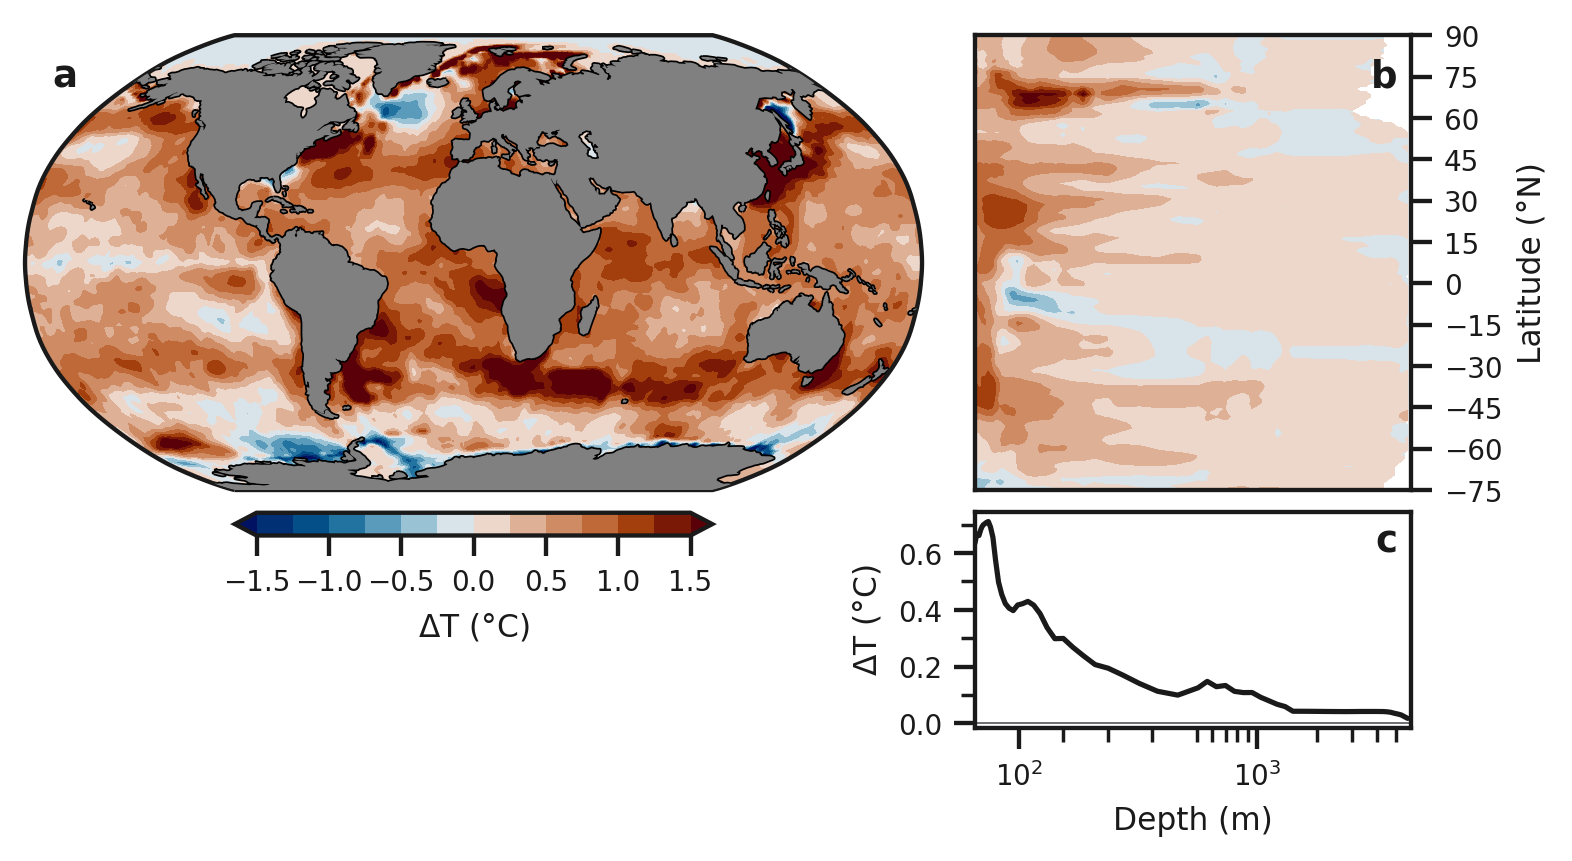

In [12]:
# one set of levels for the map and the depth section so they share a colourbar
levels = np.linspace(-1.5, 1.5, 13)
cmap = style.CMAP_DIV

fig = plt.figure()

gs = fig.add_gridspec(3,3,wspace=0.1,hspace=0.1)
ax_map = fig.add_subplot(gs[:2,:-1],projection=crs.Robinson())

ax_lat = fig.add_subplot(gs[:2,-1])
ax_z = fig.add_subplot(gs[2:,-1])

## plot map
p_map = sst.plot.contourf(ax=ax_map,cmap=cmap,levels=levels,extend='both',transform=crs.PlateCarree(),add_colorbar=False)

## plot depth
p_lat = zonal.sel(lat=slice(-75,90)).plot.contourf(ax=ax_lat,x='z',y='lat',cmap=cmap,levels=levels,extend='both',add_colorbar=False)

## plot line
p_z = profile.plot(ax=ax_z,color=style.INK)
ax_z.axhline(0,color=style.MUTED,lw=0.5,zorder=0)

# axes layout
## all
[a.set_title('') for a in [ax_map,ax_lat,ax_z]]
[a.set_xscale('symlog',linthresh=500,linscale=1,base=10,subs=[2,3,4,5,6,7,8,9]) for a in [ax_lat,ax_z]]
[a.set_xlim(depth.min(),depth.max()) for a in [ax_lat,ax_z]]
[a.tick_params(axis='both',labelsize=style.FS_TICK) for a in [ax_lat,ax_z]]

## map
ax_map.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '110m'),color='grey',zorder=3,lw=0)
ax_map.coastlines('110m',lw=1)

inset = ax_map.inset_axes([0+(1-0.5322)/2,-0.1,0.5322,0.05],transform=ax_map.transAxes)
cbar = plt.colorbar(p_map,cax=inset, orientation='horizontal')
cbar.set_label('$\\Delta$T (\N{DEGREE SIGN}C)',fontsize=style.FS_LABEL)
cbar.ax.tick_params(axis='both',labelsize=style.FS_TICK)

## lat
ax_lat.set_xticklabels([])
ax_lat.set_xlabel('')
ax_lat.set_yticks(np.arange(-75,91,15))
ax_lat.set_ylim(-75,90)
ax_lat.yaxis.tick_right()
ax_lat.yaxis.set_label_position("right")
ax_lat.set_ylabel('Latitude (\N{DEGREE SIGN}N)',fontsize=style.FS_LABEL)

## z
ax_z.set_ylabel('$\\Delta$T (\N{DEGREE SIGN}C)',fontsize=style.FS_LABEL)
ax_z.set_xlabel('Depth (m)',fontsize=style.FS_LABEL)
ax_z.yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(0.2))
ax_z.yaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(0.1))
# the seaborn white style switches tick marks off
ax_z.tick_params(axis='both',which='both',bottom=True,left=True)

style.panel_label(ax_map, 'a')
# top-left of b and c is covered by the shading/profile, so label those top-right
style.panel_labels([ax_lat, ax_z], letters='bc', x=0.97, ha='right')

# fig layout
fig_aspect = 1/2
fig.patch.set_facecolor('xkcd:white')
fig.set_size_inches(style.REF_WIDTH,style.REF_WIDTH*fig_aspect)
fig.dpi=250
plt.tight_layout(w_pad=1)

style.save(fig, 'THESIS_INTRO_ocean_deltas_{}'.format(EXPERIMENT), directory='figures', formats=('png','pdf'))